# Artificial Intelligence in Health Care - Exercise 2
## Convolutional Neural Networks for Image Classification

Mitglieder: Elbischger Selina, Krauss Marco
Jahrgang: EHT25

Das Ziel der Übung ist es ein CNN (Convolusional neural Network) zu trainieren um damit verschiedene histologische Bilder von Darmgewebe der passenden Kategorie (Darmschleimhaut, Tumorgewebe, Muskel, etc. ) zuordnen zu können.

In [1]:
#Imports and Configs
import os
os.environ["KERAS_BACKEND"] = "torch"

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

warnings.filterwarnings("ignore")
SEED = 42
keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.grid": True, "grid.alpha": 0.3})
print("keras", keras.__version__, "| backend", keras.backend.backend())

keras 3.15.1 | backend torch


## Datenimport
Im ersten Schritt wird der Datensatz importiert und in ein Trainings- Validierungs- und Testset aufgeteilt.

In [2]:
import numpy as np
#data = np.load("C:\\Users\\Marco\\Desktop\\Repos\\KIGW\\data\\path_train.npz")
data = np.load('C:\\Users\\Marco\\Desktop\\Repos\\KIGW\\data\\path_train.npz')
print(list(data.keys()))            #auflister der gespeicherten Arrays in der npz-Datei

x_train, y_train = data["x_train"], data["y_train"]
x_val,   y_val   = data["x_val"],   data["y_val"]
x_test,  y_test  = data["x_test"],  data["y_test"]

#Kontrolle mit Angabenzettel Anzahl der Daten
print(x_train.shape, x_val.shape, x_test.shape)

['x_train', 'x_val', 'x_test', 'y_train', 'y_val', 'y_test']
(89996, 28, 28, 3) (10004, 28, 28, 3) (5744, 28, 28, 3)


### 1 Data Pre-Processing and Partitioning [2P]:


* Make yourself familiar with the dataset by plotting one example image per class, arranged in
a figure of e.g. two rows, including class names and labels.   
* Prepare class labels for the use with a neural network and multi-class classification. 
* The images are given in a range of [0, 255]; normalise them to [0, 1]. 
* Report the class distribution of the training set. You will need it when you interpret the confusion matrix in tasks 2 and 3.

#### Labels in 1D Array, Klassennamen festlegen 

In [3]:
#Die Sets in 1D Arrays umwandeln, da Keras sonst Probleme hat
y_train = y_train.ravel(); 
y_val = y_val.ravel(); 
y_test = y_test.ravel()  

#Klassen aus Angabe übernommen, da die Klassenbezeichnungen nicht importiert wird wie bei medmnist
CLASSES = ["ADI", "BACK", "DEB", "LYM", "MUC", "MUS", "NORM", "STR", "TUM"]


#### Beispielbild pro Klasse
Für einen Überblick über den Datensatz wird pro Klasse ein Beispielbild angezeigt.

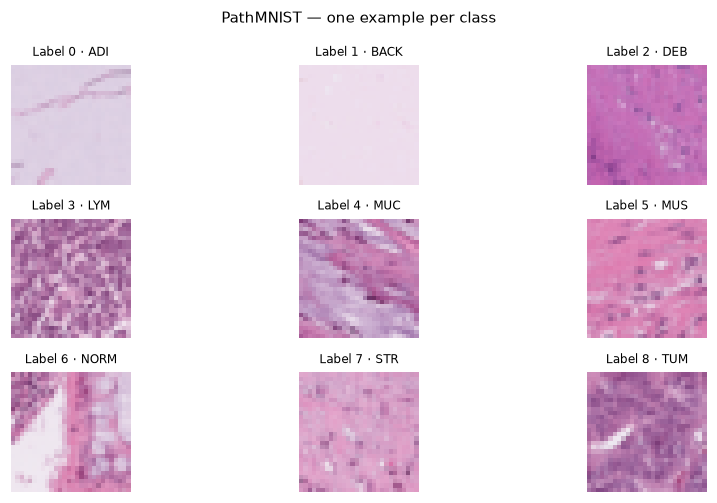

In [4]:

fig, axes = plt.subplots(3, 3, figsize=(9, 4.6))
for i, ax in enumerate(axes.ravel()):                            #axes.ravel() gibt ein eindimensionales Array der Achsen zurück -> weil die sind derzeit 3x3 angeordnet
        ax.imshow(x_train[np.where(y_train == i)[0][0]])         #[np...] -> # Index des ersten Bildes der Klasse i
        ax.set_title(f"Label {i} · {CLASSES[i]}", fontsize=8)
        ax.axis("off")
fig.suptitle("PathMNIST — one example per class", fontsize=10)
plt.tight_layout(); plt.show()

#### Klassenverteilung des Trainingsset (y_train)
Die Majority-Class Baseline Accuracy ist ein Vergleichswert, der angibt, welcher Anteil der Testbilder richtig zugeordnet würde, wenn man alle Bilder der häufigsten Klasse zuordnet. Sie ist ein guter Ausgangspunkt für den Vergleich mit dem FNN und dem CNN, da man so sieht, wie viel besser die Modelle gegenüber dieser einfachen Regel abschneiden.  

In [5]:
#Ausgabe der Datensatzgrößen und Klassenverteilung
print("train / val / test:", len(y_train), len(y_val), len(y_test))         # Anzahl der Bilder in jedem Set
print("image shape       :", x_train.shape[1:])                             # Größe der Bilder Trainingsset
print("classes           :", len(CLASSES))                                  # Anzahl der Klassen
for i, c in enumerate(CLASSES):                                     #c=eine Klasse  i=Position in der Liste
    print(f"  {i}  {c:<28} {(y_train==i).sum():>6} {100*(y_train==i).mean():>5.1f}%")       #orange Zahlen -> Formartierung
print()
print("majority-class baseline accuracy: %.3f" % (np.bincount(y_test).max()/len(y_test)))

train / val / test: 89996 10004 5744
image shape       : (28, 28, 3)
classes           : 9
  0  ADI                            9366  10.4%
  1  BACK                           9509  10.6%
  2  DEB                           10360  11.5%
  3  LYM                           10401  11.6%
  4  MUC                            8006   8.9%
  5  MUS                           12182  13.5%
  6  NORM                           7886   8.8%
  7  STR                            9401  10.4%
  8  TUM                           12885  14.3%

majority-class baseline accuracy: 0.186


#### Bilder auf [0, 1] normalisieren

In [6]:
#auf 0-1 normalisieren -> wichtig für NN zum lernen ; Bildinformation bleibt erhalen weil 128 ist dann irgendein Kommawert 0,5xy
x_train = x_train.astype("float32") / 255.0
x_val   = x_val.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

#Check min und max wert, sollte 0 und 1 sein
print(x_train.min(), x_train.max())   

0.0 1.0


#### Labels One-Hot-kodieren

In [7]:
#Klassenlabels für One-Hot-Encoding vorbereiten
num_classes = len(CLASSES)

y_train_oh = keras.utils.to_categorical(y_train, num_classes)
y_val_oh   = keras.utils.to_categorical(y_val,   num_classes)
y_test_oh  = keras.utils.to_categorical(y_test,  num_classes)

#checken, ob die One-Hot-Encoding richtig funktioniert hat -> erste 3 labels ausgeben und die Form des Arrays
print(y_train[:3]); 
print(y_train_oh[:3]); 
print(y_train_oh.shape)

[0 4 7]
[[1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0.]]
(89996, 9)


#### 2 Fully-Connected Neural Network [3P]:

First implement a dense neural network with 3 hidden layers (1024, 512 and 128 units) with
relu activation and an output layer using softmax activation. For training, use the categorical
cross-entropy loss, early stopping on the validation set V, and e.g. the Adam optimizer with an
initial learning rate of α = 0.001. Consider the use of Dropout layers.
In contrast to Exercise 1, the input data here are images. To pass them to a dense network,
flatten them in the input layer using keras.layers.Flatten. Plot the learning curves for the training and validation set (loss and accuracy). Evaluate the
classification performance (accuracy, confusion matrix, AUROC) on the test set. Report the
number of trainable parameters to compare it against the CNN.

In [8]:
#Fuktion zum Kompilieren, Trainieren und Evaluieren des Modells inkl. Ausgabe
def train_model(model, epochs=50, tag=""):
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss=keras.losses.CategoricalCrossentropy(),
                  metrics=[keras.metrics.CategoricalAccuracy(name="acc")])

    #Early Stopping -> verhinder Overfitting -> validierunsfehler überwachen ; wenn nach 5 Epochen keine Verbesserung -> abbruch & besten Gewichte
    es = keras.callbacks.EarlyStopping(monitor="val_acc", mode="max",
                                       patience=5, restore_best_weights=True)

    #Model trainieren
    h = model.fit(x_train, y_train_oh,                  #Trainingsdaten und korrekte Labels
                  validation_data=(x_val, y_val_oh),    #Validierungsdaten und korrekte Labels
                  epochs=epochs,
                  batch_size=128,                       #Anzahl der Bilder für die Berechnung des Gradienten/Gewicht pro Epoche
                  verbose=0, callbacks=[es])
    
    prob = model.predict(x_test, verbose=0)             #Wahrscheinlichkeiten für jede Klasse eines Testbild
    pred = prob.argmax(1)                               #Index der Klasse mit der höchsten Wahrscheinlichkeit pro Testbild -> liefert eindimensionales Array
    
    acc = accuracy_score(y_test, pred)                  #Anteil der korrekt klassifizierten Testbilder
    auc = roc_auc_score(y_test, prob, multi_class="ovr", average="macro")       #ovr=one-vs-rest, average=macro -> Mittelwert über alle Klassen
    
    n_par = model.count_params()
    print(f"{tag:<22} test accuracy {acc:.4f}   macro AUROC {auc:.4f}   "
          f"parameters {n_par:,}   epochs {len(h.history['loss'])}")
    return dict(tag=tag, model=model, hist=h, acc=acc, auc=auc, params=n_par,
                prob=prob, pred=pred)


#Netzwerkarchitektur definieren
keras.utils.set_random_seed(SEED)
dense = keras.Sequential([
    layers.Input(shape=(28, 28, 3)),
    layers.Flatten(),                      # 28*28*3 = 2352 numbers, geometry gone
    layers.Dense(1024, activation="relu"),
    #layers.Dropout(0.3),
    layers.Dense(512, activation="relu"),
    #layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(CLASSES), activation="softmax"),         # softmax = Wahrscheinlichkeitsverteilung über mehrere klassen (Gesamt=1)
    ], name="dense")

res_dense = train_model(dense, tag="dense network")

dense network          test accuracy 0.5587   macro AUROC 0.9197   parameters 3,001,097   epochs 21


Das FNN wurde zunächst mit und danach ohne Dropout trainiert. In den Ergebnissen zeigte sich ein deutlicher Unterschied. Das Modell ohne Dropout erreichte eine Macro-AUROC von rund 92 % und eine Accuracy von rund 55 %. Das Modell mit zwei Dropout-Schichten und einer Rate von jeweils 0,3 erreichte dagegen eine Macro-AUROC von 82 % und eine Accuracy von 43 %. Da das Modell ohne Dropout bei beiden Kennzahlen besser abschnitt, wird es für den späteren Vergleich mit dem CNN herangezogen.

#### Lernkurve Dense

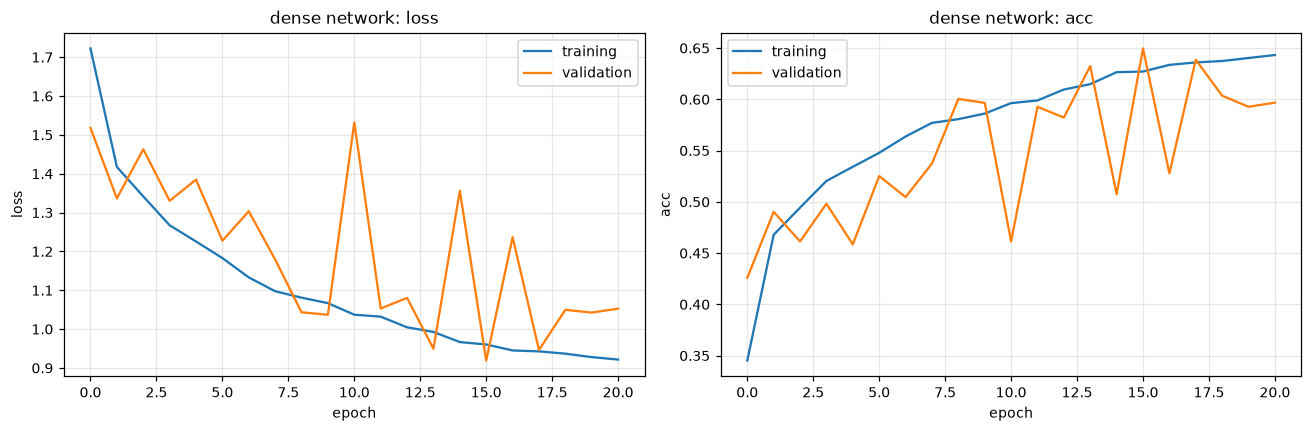

In [9]:
#Lernkurven (loss und acc)
h = res_dense["hist"].history
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, m in enumerate(["loss", "acc"]):
    ax[i].plot(h[m], label="training")
    ax[i].plot(h[f"val_{m}"], label="validation")
    ax[i].set_xlabel("epoch"); ax[i].set_ylabel(m)
    ax[i].set_title(f"dense network: {m}"); ax[i].legend()
plt.tight_layout(); plt.show()

Das Early Stopping griff nach 21 Epochen. Links ist erkennbar, dass der Validierungsfehler zwar abnimmt aber stark schwanktt. Auch die Validierungsaccuracy verbessert sich im Laufe des Trainings, schwankt jedoch ebenfalls. Der höchstwert der Validierungsaccuracy lag bei circa 60% in Epoche 20. Danach erreichte das Modell in den folgenden fünf Epochen keine weitere Verbesserung weshalb das Trainings gestoppt wurde (patience=5).

#### Confusion Matrix Dense TEST

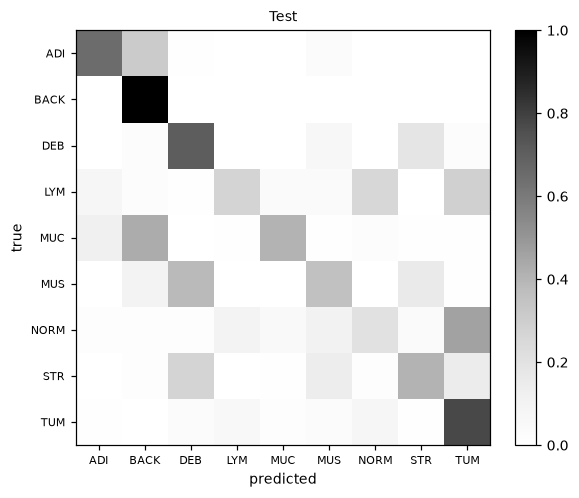

ADI   recall 0.650
BACK  recall 1.000
DEB   recall 0.706
LYM   recall 0.270
MUC   recall 0.403
MUS   recall 0.359
NORM  recall 0.207
STR   recall 0.406
TUM   recall 0.774

Schwächste Klasse in dense network: 6 · NORM  (recall 0.207)
am häufigsten verwechselt mit: TUM


In [10]:
cm = confusion_matrix(y_test, res_dense["pred"])
fig, ax = plt.subplots(figsize=(5.4, 4.6))
im = ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Greys", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES))); ax.set_yticks(range(len(CLASSES)))
ax.set_xticklabels(CLASSES, fontsize=7); ax.set_yticklabels(CLASSES, fontsize=7)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Test", fontsize=9)
ax.grid(False); plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

per_class = cm.diagonal() / cm.sum(1)
for c, r in zip(CLASSES, per_class):
    print(f"{c:<5} recall {r:.3f}")


#schlechte Klasse und mit welcher Klasse sie am häufigsten verwechselt wird
worst = per_class.argmin() 
print("")
print(f"Schwächste Klasse in {res_dense['tag']}: {worst} · {CLASSES[worst]}  (recall {per_class[worst]:.3f})")
mistakes = cm[worst].copy()     #vorhersagen der schwächsten horizontalen Klasse 
mistakes[worst] = 0     #die korrekten Vorhersagen der schwächsten Klasse auf 0 setzen -> wenn man dann argmax sucht hat man die klasse die am häufigsten mit der richtigen Klasse verwechselt wird
confused_with = mistakes.argmax()      #Index der Klasse, mit der die schwächste Klasse am häufigsten verwechselt wird   
print(f"am häufigsten verwechselt mit: {CLASSES[confused_with]}")

**WH Recall:** „Von allen Bildern, die tatsächlich zu dieser Klasse gehören, wie viele hat das Modell richtig erkannt?“  

Das Dense-Netzwerk erkennt die Klassen BACK (Hintergrund) besonders gut -> Alle Bilder werden richtig zugeorndet (recall = 1). Am schlechtesten erkennt das Netzwerk die Klasse NORM (normale Darmschleimhaut). Bilder dieser Klasse werden am häufigsten mit TUM (Tumorepithel) verwechselt.

### 3 Convolutional Neural Network [5P]:

Now implement a Convolutional Neural Network for classification of the 9 tissue types. In the
first stage use a convolutional architecture built from Conv2D and MaxPooling2D layers. In the
second stage use a fully-connected classification network. Do not forget to flatten the output of
the convolutional stage before passing it to the fully-connected part. Again use the categorical
cross-entropy loss and early stopping on V.
Plot the learning curves for the training and validation set. Evaluate the classification perfor-
mance (accuracy, confusion matrix, AUROC) on the test set. Try to achieve an accuracy as high
as possible (at least 70 %).
Summarise the performance measures from tasks 2 and 3 in a table and interpret the results.
Include the parameter count for both models and comment on what you find.

In [11]:
#CNN-Architektur definieren -> first conv2D & MaxPooling 2D -> second flatten and dense
keras.utils.set_random_seed(SEED)
cnn = keras.Sequential([
    layers.Input(shape=(28, 28, 3)),

    layers.Conv2D(32, 3, activation="relu", padding="same"), # Convolutional layer with 32 filters of size 3x3
    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(2),                # 28x28 -> 14x14

    layers.Conv2D(64, 3, activation="relu", padding="same"), # Convolutional layer with 64 filters of size 3x3
    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(2),                # 14x14 -> 7x7

    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(CLASSES), activation="softmax"),
], name="cnn")

cnn.summary()

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 468,265 (1.79 MB)

 Trainable params: 468,265 (1.79 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
#Modell trainieren
res_cnn = train_model(cnn, tag="convolutional network")

convolutional network  test accuracy 0.8430   macro AUROC 0.9821   parameters 468,265   epochs 20


Das CNN erreicht mit 84,3 % Accuracy und einer AUROC von 0,982 deutlich bessere Werte als das Dense-Netz (92% AROUC bzw. 62% Accuracy). Mit rund 468.000 Parametern hat es zudem lediglich 1/6 der Paramteranzahl als das dense-Netz.

#### Lernkurve CNN

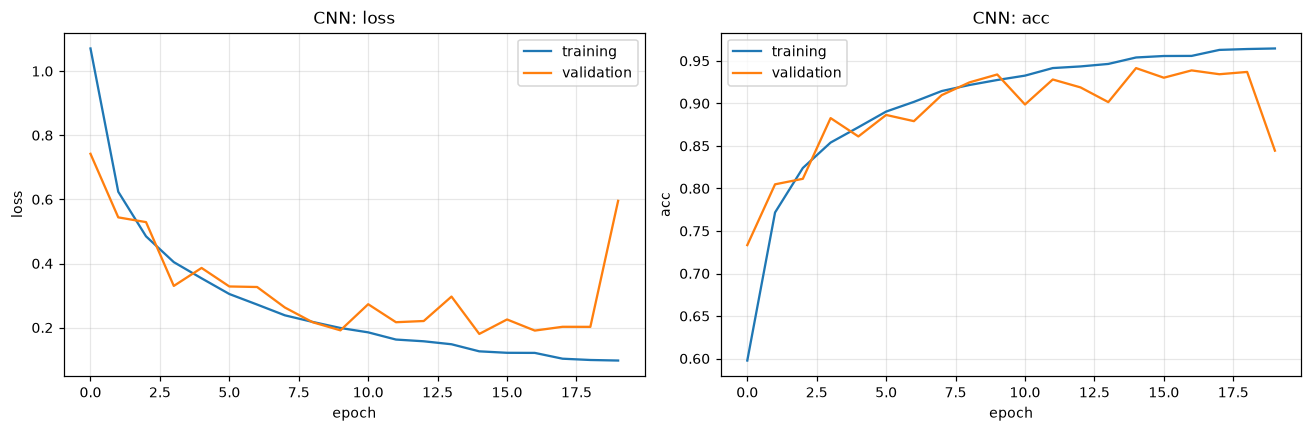

In [ ]:
#Lernkurven CNN (loss und acc)
h = res_cnn["hist"].history
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, m in enumerate(["loss", "acc"]):
    ax[i].plot(h[m], label="training")
    ax[i].plot(h[f"val_{m}"], label="validation")
    ax[i].set_xlabel("epoch"); ax[i].set_ylabel(m)
    ax[i].set_title(f"CNN: {m}"); ax[i].legend()
plt.tight_layout(); plt.show()

Die Lernkurven des CNN wirken im Vergleich zum Dense-Netz insgesamt stabiler. Der Trainingsfehler sinkt über den gesamten Lauf, während der Validierungsfehler zu Beginn deutlich abnimmt und später (ab Epoche 8) meist um 0,2 schwankt. Ab der 17. Epoche beginnt dieser dann anzusteigen was auf overfitting hindeutet. Die Validierungsaccuracy liegt nahe an der Trainingsaccuracy. Auch hier ist ab der 17. Epoche erkennbar, dass die Accuracy des Validierungsdatensatzes von circa 94% auf 85% fällt. Da sich die Trainingswerte weiterhin leicht verbessern, deutet dieses Auseinanderlaufen auf Overfitting hin.

#### confusion Matrix CNN

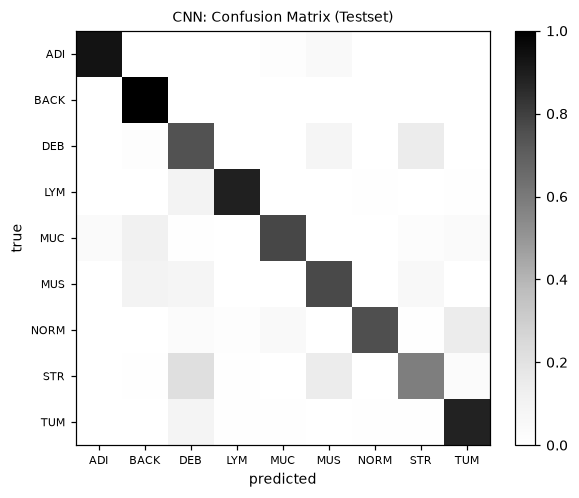

ADI   recall 0.931
BACK  recall 1.000
DEB   recall 0.747
LYM   recall 0.890
MUC   recall 0.779
MUS   recall 0.770
NORM  recall 0.755
STR   recall 0.586
TUM   recall 0.880

Schwächste Klasse in convolutional network: 7 · STR  (recall 0.586)
am häufigsten verwechselt mit: DEB


In [14]:
#Confusion Matrix CNN
cm_cnn = confusion_matrix(y_test, res_cnn["pred"])
fig, ax = plt.subplots(figsize=(5.4, 4.6))
im = ax.imshow(cm_cnn / cm_cnn.sum(1, keepdims=True), cmap="Greys", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES))); ax.set_yticks(range(len(CLASSES)))
ax.set_xticklabels(CLASSES, fontsize=7); ax.set_yticklabels(CLASSES, fontsize=7)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("CNN: Confusion Matrix (Testset)", fontsize=9)
ax.grid(False); plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

per_class_cnn = cm_cnn.diagonal() / cm_cnn.sum(1)
for c, r in zip(CLASSES, per_class_cnn):
    print(f"{c:<5} recall {r:.3f}")

#schlechte Klasse und mit welcher Klasse sie am häufigsten verwechselt wird
worst = per_class_cnn.argmin() 
print("")
print(f"Schwächste Klasse in {res_cnn['tag']}: {worst} · {CLASSES[worst]}  (recall {per_class_cnn[worst]:.3f})")
mistakes = cm_cnn[worst].copy()     #vorhersagen der schwächsten horizontalen Klasse 
mistakes[worst] = 0     #die korrekten Vorhersagen der schwächsten Klasse auf 0 setzen -> wenn man dann argmax sucht hat man die klasse die am häufigsten mit der richtigen Klasse verwechselt wird
confused_with = mistakes.argmax()      #Index der Klasse, mit der die schwächste Klasse am häufigsten verwechselt wird   
print(f"am häufigsten verwechselt mit: {CLASSES[confused_with]}")

Das CNN erkennt alle Bilder der Klasse BACK (Hintergrund) auch korrekt als BACK und erkennt diese somit am besten (recall = 1). Am schlechtesten erkannt wird die Klasse STR (tumorassoziiertes Stroma) welches lediglich einen recall von 58% aufweist und am häufigsten mit der Klasse DEB (Zelltrümmer) verwechselt wurde.
Interessant -> das Modell wurde zweimal trainiert und bei beiden war zwar der recall bei STR am schlechtesten allerdings beim ersten mal war er mit 37% sehr viel schlechter.

### Summary

Abschließend wollen wir beide Ergenisse (FNN und CNN) vergleichen.

In [15]:
#Vergleichstabelle Dense vs. CNN
results = [res_dense, res_cnn]
names = ["Dense-Netz", "CNN"]

table = pd.DataFrame({
    "Test-Accuracy": [r["acc"] for r in results],
    "Macro AUROC":   [r["auc"] for r in results],
    "Parameter":     [r["params"] for r in results],
    "Epochen":       [len(r["hist"].history["loss"]) for r in results],
}, index=names)

display(table.style.format({"Test-Accuracy": "{:.3f}", "Macro AUROC": "{:.3f}",
                            "Parameter": "{:,}"}))
print(f"Das CNN hat {res_dense['params'] / res_cnn['params']:.1f} x weniger Parameter")
print(f"Accuracy-Unterschied: {res_cnn['acc'] - res_dense['acc']:+.3f}")

,Test-Accuracy,Macro AUROC,Parameter,Epochen
Dense-Netz,0.559,0.920,"3,001,097",21
CNN,0.843,0.982,"468,265",20


Das CNN hat 6.4 x weniger Parameter
Accuracy-Unterschied: +0.284


In [16]:
#Für jedes Modell die Confusion Matrix berechnen und Recall pro Klasse (Testset)
cms = [confusion_matrix(y_test, r["pred"]) for r in results]

#Recall pro Klasse: Dense vs. CNN und in Tabelle speichern (n: Spaltenüberschrift) 
recall = pd.DataFrame({n: c.diagonal() / c.sum(1) for n, c in zip(names, cms)},     #zip -> verbindet Modellnamen mit Confusionmatrix
                      index=CLASSES)

#Differenz des Recalls berechnen
recall["Differenz"] = recall["CNN"] - recall["Dense-Netz"]
display(recall.style.format("{:.3f}"))

,Dense-Netz,CNN,Differenz
ADI,0.650,0.931,0.281
BACK,1.000,1.000,0.000
DEB,0.706,0.747,0.041
LYM,0.270,0.890,0.620
MUC,0.403,0.779,0.377
MUS,0.359,0.770,0.411
NORM,0.207,0.755,0.548
STR,0.406,0.586,0.180
TUM,0.774,0.880,0.106


Das CNN errreicht bei 7 von 9 Klassen einen höheren Recall als das FNN. Die Klasse mit den HIntergrundbildern wird von beiden Netzwerken vollständig erkannt. Beim tumorassizierten Stroma ist das CNN mit einerm recall von 37,1% minimal schlechter als das FNN (recall = 38%). Mit einem Recallunterschied von 0,775 ist erkannt das CNN die Klasse NORM (normale Darmschleimhaut) besser als das FNN.

### Bonus Try

#### Augmentation


Bei der Augmentation werden die Bilder im Trainingsdatensatz leicht verändert. Dazu werden sie zufällig gedreht oder gespiegelt. Zusätzlich werden ihre Farbwerte und ihr Kontrast leicht verändert. So entstehen beim Training zusätzliche Varianten der vorhandenen Bilder. Dadurch kann das CNN lernen, dieselbe Gewebeklasse auch bei anderer Ausrichtung oder Färbung zu erkennen.

In [ ]:
#Augmentation: Drehung/Spiegelung + Farbveränderung (simuliert andere Färbung)
class AugmentedData(keras.utils.PyDataset):
    #Bilder und Labels speichern, der Zufallsgenerator einrichten und die Bildindexe mischen
    def __init__(self, x, y, batch_size=128, seed=0, **kwargs):
        super().__init__(**kwargs)                      #ZUsatzargumente für keras
        self.x, self.y, self.bs = x, y, batch_size
        self.rng = np.random.default_rng(seed)          #Zufallsgenerator -> später für mischen bzw zufällige Bildänderungen
        self.idx = np.arange(len(x))                    #Pos pro bild speichern
        self.rng.shuffle(self.idx)                      #Positionen durch zufallsgenerator mischen

    #Anzahl der Batches berechnen
    def __len__(self):
        return int(np.ceil(len(self.x) / self.bs))      #np.ceil -> aufrunden das einfach ein nicht vollständiges batch zum schluss entstehen würde

    #Führt die Bildveränderungen pro Batch durch
    def __getitem__(self, i):
        b = self.idx[i * self.bs:(i + 1) * self.bs]         #betroffenen Bildindexe speichern
        xb = self.x[b].copy()                               #Bilder mit den indexen aus b in Kopie speichern und daruaf weiter arbeiten
        n = len(xb)

        #Geometrie: zufällige 90°-Drehung und Spiegelung pro Bild
        for j in range(n):
            img = np.rot90(xb[j], self.rng.integers(4))
            if self.rng.random() < 0.5:
                img = img[:, ::-1]
            xb[j] = img

             #Farbe: jeder Kanal leicht verstärkt/verschoben (andere Färbung)
        xb = xb * self.rng.uniform(0.94, 1.06, (n, 1, 1, 3)) \
                + self.rng.uniform(-0.03, 0.03, (n, 1, 1, 3))
        #Kontrast
        mean = xb.mean(axis=(1, 2, 3), keepdims=True)
        xb = (xb - mean) * self.rng.uniform(0.85, 1.15, (n, 1, 1, 1)) + mean

        return np.clip(xb, 0, 1).astype("float32"), self.y[b]

    #Am ende jeder Epoche -> Bilder Reihenfolge mischen 
    def on_epoch_end(self):
        self.rng.shuffle(self.idx)

#### Augmentations Check

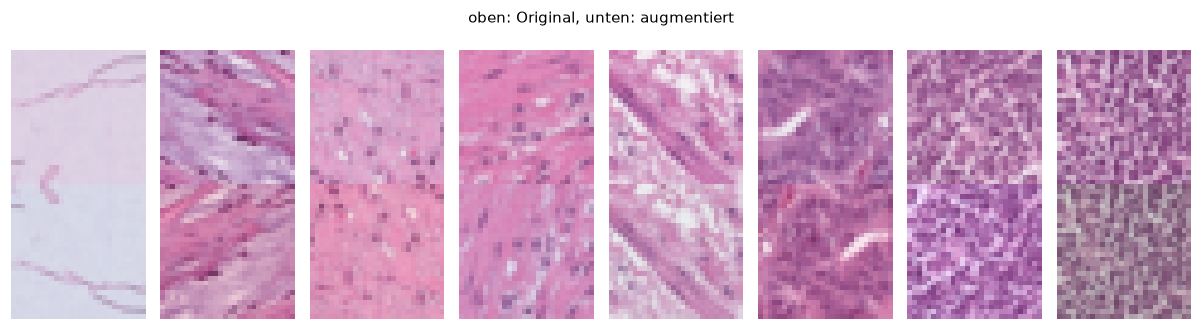

In [ ]:
#Kontrolle: oben Original, unten augmentiert
demo = AugmentedData(x_train, y_train_oh, batch_size=8, seed=1)     #augmentierten trainings Demo Datnensatz erstellen (immer 8 bilder zum testen)
demo.idx = np.arange(8)          #immer dieselben 8 Bilder zeigen
xb, _ = demo[0]                  #ersten 8 Bilder holen
fig, axes = plt.subplots(2, 8, figsize=(11, 3))
for j in range(8):      #jedes der 8 Bilder anzeigen
    axes[0, j].imshow(x_train[j]); axes[0, j].axis("off")
    axes[1, j].imshow(xb[j]);      axes[1, j].axis("off")
fig.suptitle("oben: Original, unten: augmentiert", fontsize=10)
plt.tight_layout(); plt.show()

#### Modell

In [ ]:
#zwei Conv-Schichten mit Batch Normalization, dann Pooling
def conv_block(x, n):
    x = layers.Conv2D(n, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(n, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    return layers.MaxPooling2D(2)(x)            #Bild verkleinern -> pro 2x2 Feld den größten wert nehmen

def build_cnn(seed):
    keras.utils.set_random_seed(seed)
    inp = layers.Input(shape=(28, 28, 3))       #erwartet pro bild eine größe von 28x28x3 Kanäle
    z = conv_block(inp, 32)                 # 28 -> 14
    z = conv_block(z, 64)                   # 14 -> 7   # immer mit der endausgabe vom vorigen block weiterarebiten
    z = conv_block(z, 128)                  # 7  -> 3
    z = layers.GlobalAveragePooling2D()(z)  #aus den 3x3 merkmalen wird ein durchschnittsmittelwert
    z = layers.Dropout(0.3)(z)
    out = layers.Dense(len(CLASSES), activation="softmax")(z)           #Die Wahrscheinlihckeiten pro Gewebeklasse ausgeben -> summe = 1
    return keras.Model(inp, out, name=f"cnn_bonus_s{seed}")

def train_bonus(model, seed, epochs=60):
    model.compile(
        optimizer=keras.optimizers.AdamW(1e-3, weight_decay=1e-4),
        loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),         #sorgt dafür dass das Modell im Laufe der zeit nicht immer eher 100% vorhersagt
        metrics=[keras.metrics.CategoricalAccuracy(name="acc")])

    #early stopping nach keiner besserung der acc innerhalb von patience -> besten gewichte speichern
    cbs = [keras.callbacks.EarlyStopping(monitor="val_acc", mode="max",
                                         patience=10, restore_best_weights=True),
           #nach patience ohne verbesserung der validierungs loss -> lernrate halbieren (nicht unter min_lr) -> damit nicht über das minimum springen kann wenn zu große shritte sind
           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                             patience=3, min_lr=1e-5)]
    #model trainiern auf den veränderten bildern; validierung am original
    return model.fit(AugmentedData(x_train, y_train_oh, seed=seed),
                     validation_data=(x_val, y_val_oh),
                     epochs=epochs, verbose=1, callbacks=cbs)

#Evaluierung des Modells anhand der Testbilder
def evaluate(model, tag):
    prob = model.predict(x_test, verbose=0, batch_size=512)
    pred = prob.argmax(1)           #höchste wahrscheinlichkeit entspricht der vorhersage
    acc = accuracy_score(y_test, pred)
    auc = roc_auc_score(y_test, prob, multi_class="ovr", average="macro")
    print(f"{tag:<22} test accuracy {acc:.4f}   macro AUROC {auc:.4f}   "
          f"parameters {model.count_params():,}")
    return dict(tag=tag, model=model, acc=acc, auc=auc,
                params=model.count_params(), prob=prob, pred=pred)

#### Erstes Modell

In [20]:
m1 = build_cnn(seed=42)
h1 = train_bonus(m1, seed=42)
res_b1 = evaluate(m1, "bonus CNN (1 Modell)")

Epoch 1/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 148s 210ms/step - acc: 0.7640 - loss: 1.0231 - val_acc: 0.7032 - val_loss: 1.1431 - learning_rate: 0.0010
Epoch 2/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 147s 209ms/step - acc: 0.8888 - loss: 0.7699 - val_acc: 0.6376 - val_loss: 1.4747 - learning_rate: 0.0010
Epoch 3/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 149s 212ms/step - acc: 0.9160 - loss: 0.7104 - val_acc: 0.3776 - val_loss: 2.0450 - learning_rate: 0.0010
Epoch 4/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 149s 211ms/step - acc: 0.9289 - loss: 0.6830 - val_acc: 0.5617 - val_loss: 1.4783 - learning_rate: 0.0010
Epoch 5/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 147s 209ms/step - acc: 0.9431 - loss: 0.6478 - val_acc: 0.8668 - val_loss: 0.8093 - learning_rate: 5.0000e-04
Epoch 6/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 148s 210ms/step - acc: 0.9472 - loss: 0.6396 - val_acc: 0.6727 - val_loss: 1.2820 - learning_rate: 5.0000e-04
Epoch 7/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 146s 207ms/step - acc: 0.9493 - loss: 0.6332 - val_acc: 0.8978 - val_loss: 0

#### Zweites und Drittes Modell probieren 

In [21]:
#Zwei weitere Modelle mit anderem Seed, dann Vorhersagen mitteln
m2 = build_cnn(seed=7);  train_bonus(m2, seed=7)
m3 = build_cnn(seed=123); train_bonus(m3, seed=123)

inp = layers.Input(shape=(28, 28, 3))
out = layers.Average()([m(inp) for m in (m1, m2, m3)])
ensemble = keras.Model(inp, out, name="cnn_ensemble")
res_ens = evaluate(ensemble, "bonus CNN (Ensemble)")

Epoch 1/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 153s 217ms/step - acc: 0.7565 - loss: 1.0377 - val_acc: 0.6402 - val_loss: 1.2452 - learning_rate: 0.0010
Epoch 2/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 153s 218ms/step - acc: 0.8881 - loss: 0.7717 - val_acc: 0.4536 - val_loss: 2.2240 - learning_rate: 0.0010
Epoch 3/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 152s 216ms/step - acc: 0.9153 - loss: 0.7117 - val_acc: 0.6982 - val_loss: 1.3219 - learning_rate: 0.0010
Epoch 4/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 153s 217ms/step - acc: 0.9293 - loss: 0.6814 - val_acc: 0.6178 - val_loss: 1.3532 - learning_rate: 0.0010
Epoch 5/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 153s 218ms/step - acc: 0.9436 - loss: 0.6472 - val_acc: 0.9218 - val_loss: 0.6820 - learning_rate: 5.0000e-04
Epoch 6/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 153s 218ms/step - acc: 0.9461 - loss: 0.6406 - val_acc: 0.8673 - val_loss: 0.8102 - learning_rate: 5.0000e-04
Epoch 7/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 154s 218ms/step - acc: 0.9497 - loss: 0.6336 - val_acc: 0.8468 - val_loss: 0

#### Prüfcode

In [22]:
#Speichern und testen, ob das geladene Modell dasselbe vorhersagt
final, res_final = ensemble, res_ens          #oder m1, res_b1, falls besser
fname = "cnn_gr_elbischger_krauss.keras"
final.save(fname)

loaded = keras.models.load_model(fname)
p = loaded.predict(x_test, verbose=0, batch_size=512)
print("identisch nach dem Laden:", np.allclose(p, res_final["prob"], atol=1e-5))

identisch nach dem Laden: True


Um das CNN aus Aufgabe 3 zu verbessern, haben wir die Trainingsbilder zufällig gedreht, gespiegelt und leicht in Farbe und Kontrast verändert. Das ist sinnvoll, weil Gewebe keine feste Ausrichtung hat und das Testset aus einer anderen Klinik mit anderer Färbung stammt. Zusätzlich haben wir ein tieferes Netz mit Batch Normalization verwendet, länger trainiert (patience = 10, Lernrate wird bei Stillstand halbiert) und drei Modelle zu einem Ensemble kombiniert. Damit steigt die Test-Accuracy von 84% auf knapp 94% (AUROC 0,99), bei weniger Parametern pro Einzelmodell. Eine Variante mit anderer Farb-Augmentation war schlechter (92,4 %), weshalb wir sie verworfen haben. Da wir die finale Variante anhand des Testsets ausgewählt haben, ist die angegebene Test-Accuracy leicht optimistisch.